# 3. Avaliação e exportação

Mede o modelo final (média de `notavelai_base` e `notavelai_external`) na validação e nas fotos do
celular, do mesmo jeito que o app. O split `test` não é usado aqui.

In [1]:
import csv
import os
import sys
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

# Permite importar src/ com o notebook aberto a partir de notebooks/ ou da raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np

from src.data.dataset import CLASSES, PROCESSED_DIR, print_table
from src.models import ensemble, evaluate
from src.models.predict import expand, load

# train_model escolhe o backend Agg ao ser importado; aqui as figuras precisam aparecer.
%matplotlib inline

# True recria os .tflite e o labels.txt em models/ a partir dos .keras.
EXPORTAR = False

## Exportação

Cada membro vira um `.tflite` float32. O int8 foi testado e descartado: errava mais que o float32.

In [2]:
if EXPORTAR:
    ensemble.export()
for path in ensemble.tflite_paths():
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

notavelai_base.tflite: 8.9 MB
notavelai_external.tflite: 8.9 MB


In [3]:
evaluate.main()

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


notavelai_base.tflite: 0 previsões diferentes do Keras


notavelai_external.tflite: 0 previsões diferentes do Keras
{'model': 'base', 'validation_correct': '64/66', 'validation_spoken_right': 44, 'validation_spoken_wrong': 1, 'phone_correct': '14/24', 'phone_spoken_right': 10, 'phone_spoken_wrong': 5}
{'model': 'external', 'validation_correct': '60/66', 'validation_spoken_right': 39, 'validation_spoken_wrong': 4, 'phone_correct': '16/24', 'phone_spoken_right': 11, 'phone_spoken_wrong': 4}
{'model': 'final', 'validation_correct': '63/66', 'validation_spoken_right': 43, 'validation_spoken_wrong': 1, 'phone_correct': '13/24', 'phone_spoken_right': 11, 'phone_spoken_wrong': 4}


Modelo final: 17.9 MB, 4.1 ms por foto (1 thread, neste computador)


## Resultados

"Fala certo" e "fala errado" contam as vezes em que o app anunciaria um valor: confiança de pelo
menos 50% e classe diferente de `fundo`. Para quem não enxerga a nota, falar um valor errado é o
pior erro. As fotos do celular são poucas (24) e também orientaram a escolha do modelo, então os
números tendem a ser otimistas.

In [4]:
with evaluate.SUMMARY_PATH.open(encoding="utf-8") as file:
    rows = list(csv.reader(file))
print_table(rows[1:], rows[0])

with evaluate.PHOTOS_PATH.open(encoding="utf-8") as file:
    errors = [[r["file"], r["true_label"], r["predicted"], r["confidence"], r["app_says"]]
              for r in csv.DictReader(file) if r["true_label"] != r["predicted"]]
print_table(errors, ["arquivo", "real", "previsto", "confiança", "app fala"])

   model  validation_correct  validation_spoken_right  validation_spoken_wrong  phone_correct  phone_spoken_right  phone_spoken_wrong
--------  ------------------  -----------------------  -----------------------  -------------  ------------------  ------------------
    base               64/66                       44                        1          14/24                  10                   5
external               60/66                       39                        4          16/24                  11                   4
   final               63/66                       43                        1          13/24                  11                   4
                arquivo   real  previsto  confiança        app fala
-----------------------  -----  --------  ---------  --------------
      1793374377214.jpg    100         5      0.471  not identified
      1793741966321.jpg      2       200      0.327  not identified
      1793374377053.jpg     20        50      0.522       

## Exemplo de inferência

Faz o mesmo caminho do app: imagem com padding preto até 224x224, valores 0–255 sem normalizar,
média dos dois `.tflite` e a classe lida de `labels.txt`. Mostra uma cédula da validação por classe.

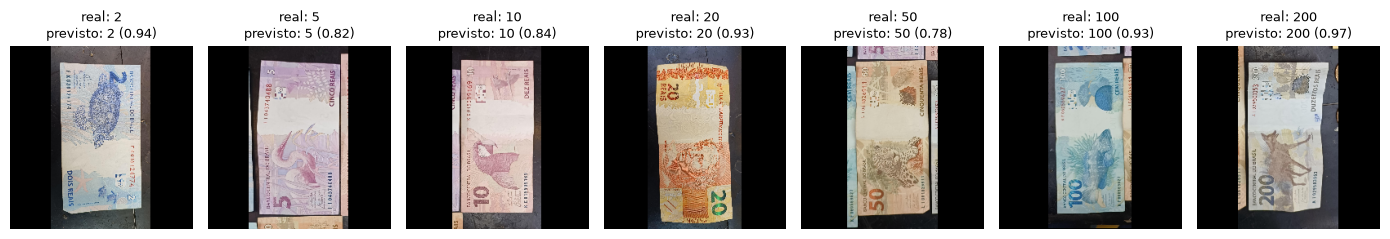

In [5]:
labels = ensemble.LABELS_PATH.read_text(encoding="utf-8").splitlines()
files = expand([PROCESSED_DIR / "valid"])
chosen = [next(f for f in files if f.parent.name == label) for label in CLASSES]
images = np.stack([load(f) for f in chosen])
probabilities = ensemble.predict(images)

figure, axes = plt.subplots(1, len(chosen), figsize=(14, 2.6))
for axis, file, image, scores in zip(axes, chosen, images, probabilities):
    axis.imshow(image.astype("uint8"))
    axis.set_title(f"real: {file.parent.name}\nprevisto: {labels[int(np.argmax(scores))]} ({scores.max():.2f})", fontsize=9)
    axis.axis("off")
figure.tight_layout()
plt.show()

## Limitações

O modelo ainda não é confiável para identificar dinheiro de verdade: nas 24 fotos do celular, o app
anuncia 11 valores certos e 4 errados, e fica em silêncio nas demais. O teste tem só 1 foto de R$ 2,
nenhuma de R$ 50 e 2 de dólar.